In [ ]:
!pip install pennylane
!pip install networks

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 85.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 53.2 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
  Preparing metadata (setup.py) ... done
  Created wheel for networks: filename=networks-0.3.7-py3-none-any.whl size=11677 sha256=61fde141ddca41bac726351d0ab7e853d39da165bf478b77be842907f1e797be
  Stored in dir

# **Two qubit MBQC Subroutine for $|11\rangle$ marked state**

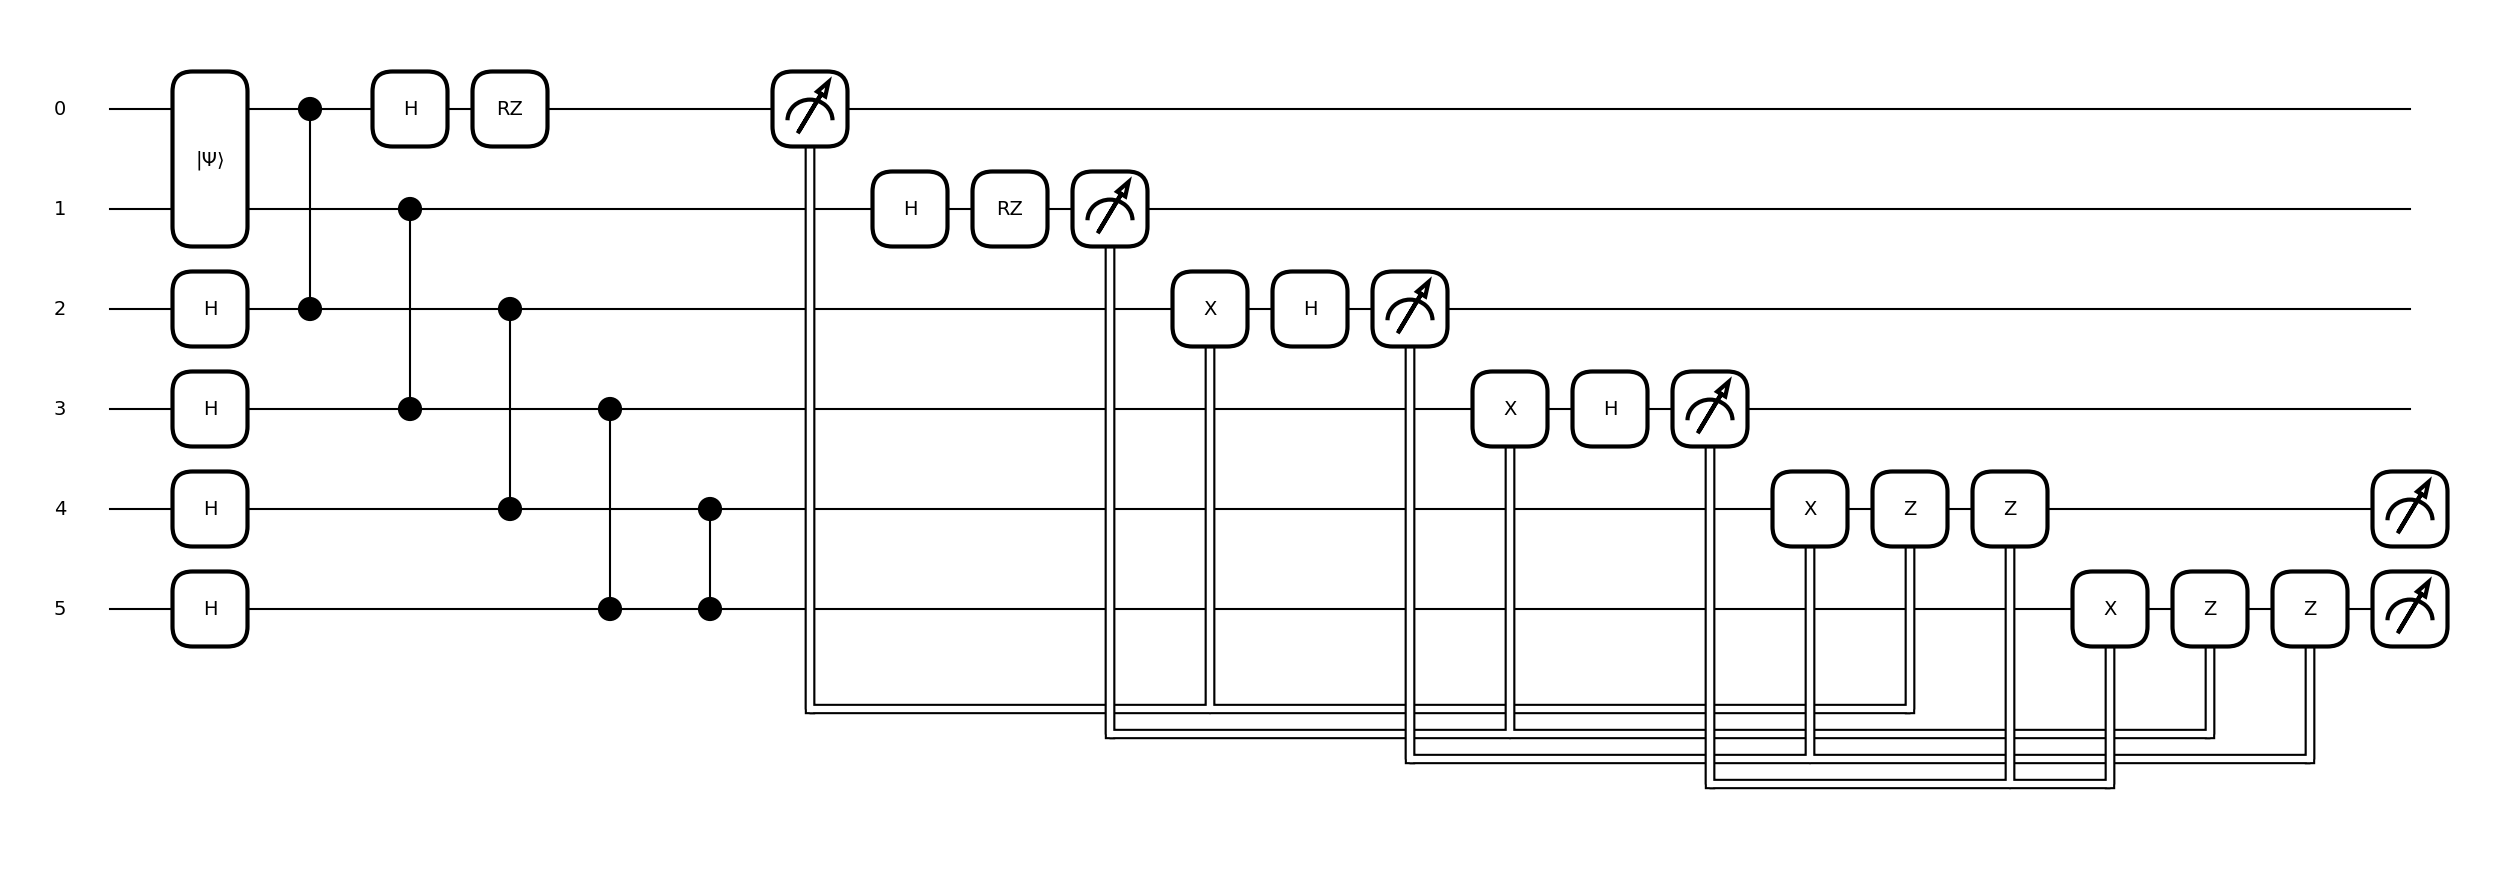

[[ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]
 [-0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]]


In [ ]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt


# MBQC CZ circuit
dev_mbqc = qml.device("default.qubit", wires=6)

@qml.qnode(dev_mbqc, interface="autograd")
def mbqc_cz(input_state):
    # Prepare the same input |ψ⟩ on qubits 0 and 1
    qml.StatePrep(input_state, wires=[0, 1])

    # Prepare ancilla cluster state (qubits 2, 3, 4, 5 in |+⟩ state)
    for w in [2, 3, 4, 5]:
        qml.Hadamard(wires=w)

    # Create cluster entanglement with CZ gates
    qml.CZ(wires=[0, 2])
    qml.CZ(wires=[1, 3])
    qml.CZ(wires=[2, 4])
    qml.CZ(wires=[3, 5])
    qml.CZ(wires=[4, 5])

    # Measure input qubits in X-basis (apply H then measure)
    qml.Hadamard(wires=0)
    qml.RZ(0,wires=0)
    m0 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    qml.RZ(0,wires=1)
    m1 = qml.measure(wires=1)

    # Measure ancilla qubits with byproduct corrections
    qml.cond(m0 == 1, qml.PauliX)(wires=2)
    qml.Hadamard(wires=2)
    m2 = qml.measure(wires=2)

    qml.cond(m1 == 1, qml.PauliX)(wires=3)
    qml.Hadamard(wires=3)
    m3 = qml.measure(wires=3)

    # Apply corrections to output qubits based on measurement outcomes
    qml.cond(m2 == 1, qml.PauliX)(wires=4)
    qml.cond(m0 == 1, qml.PauliZ)(wires=4)
    qml.cond(m3 == 1, qml.PauliZ)(wires=4)

    qml.cond(m3 == 1, qml.PauliX)(wires=5)
    qml.cond(m1 == 1, qml.PauliZ)(wires=5)
    qml.cond(m2 == 1, qml.PauliZ)(wires=5)

    # Return the density matrix of the logical output qubits (4, 5)
    return qml.density_matrix(wires=[4, 5])

input_state = np.array([1, -1, 1, -1], dtype=complex) / 2

fig, ax = qml.draw_mpl(mbqc_cz)(input_state)
plt.show()


print(mbqc_cz(input_state))

# **Two qubit MBQC Subroutine for $|10\rangle$ marked state**

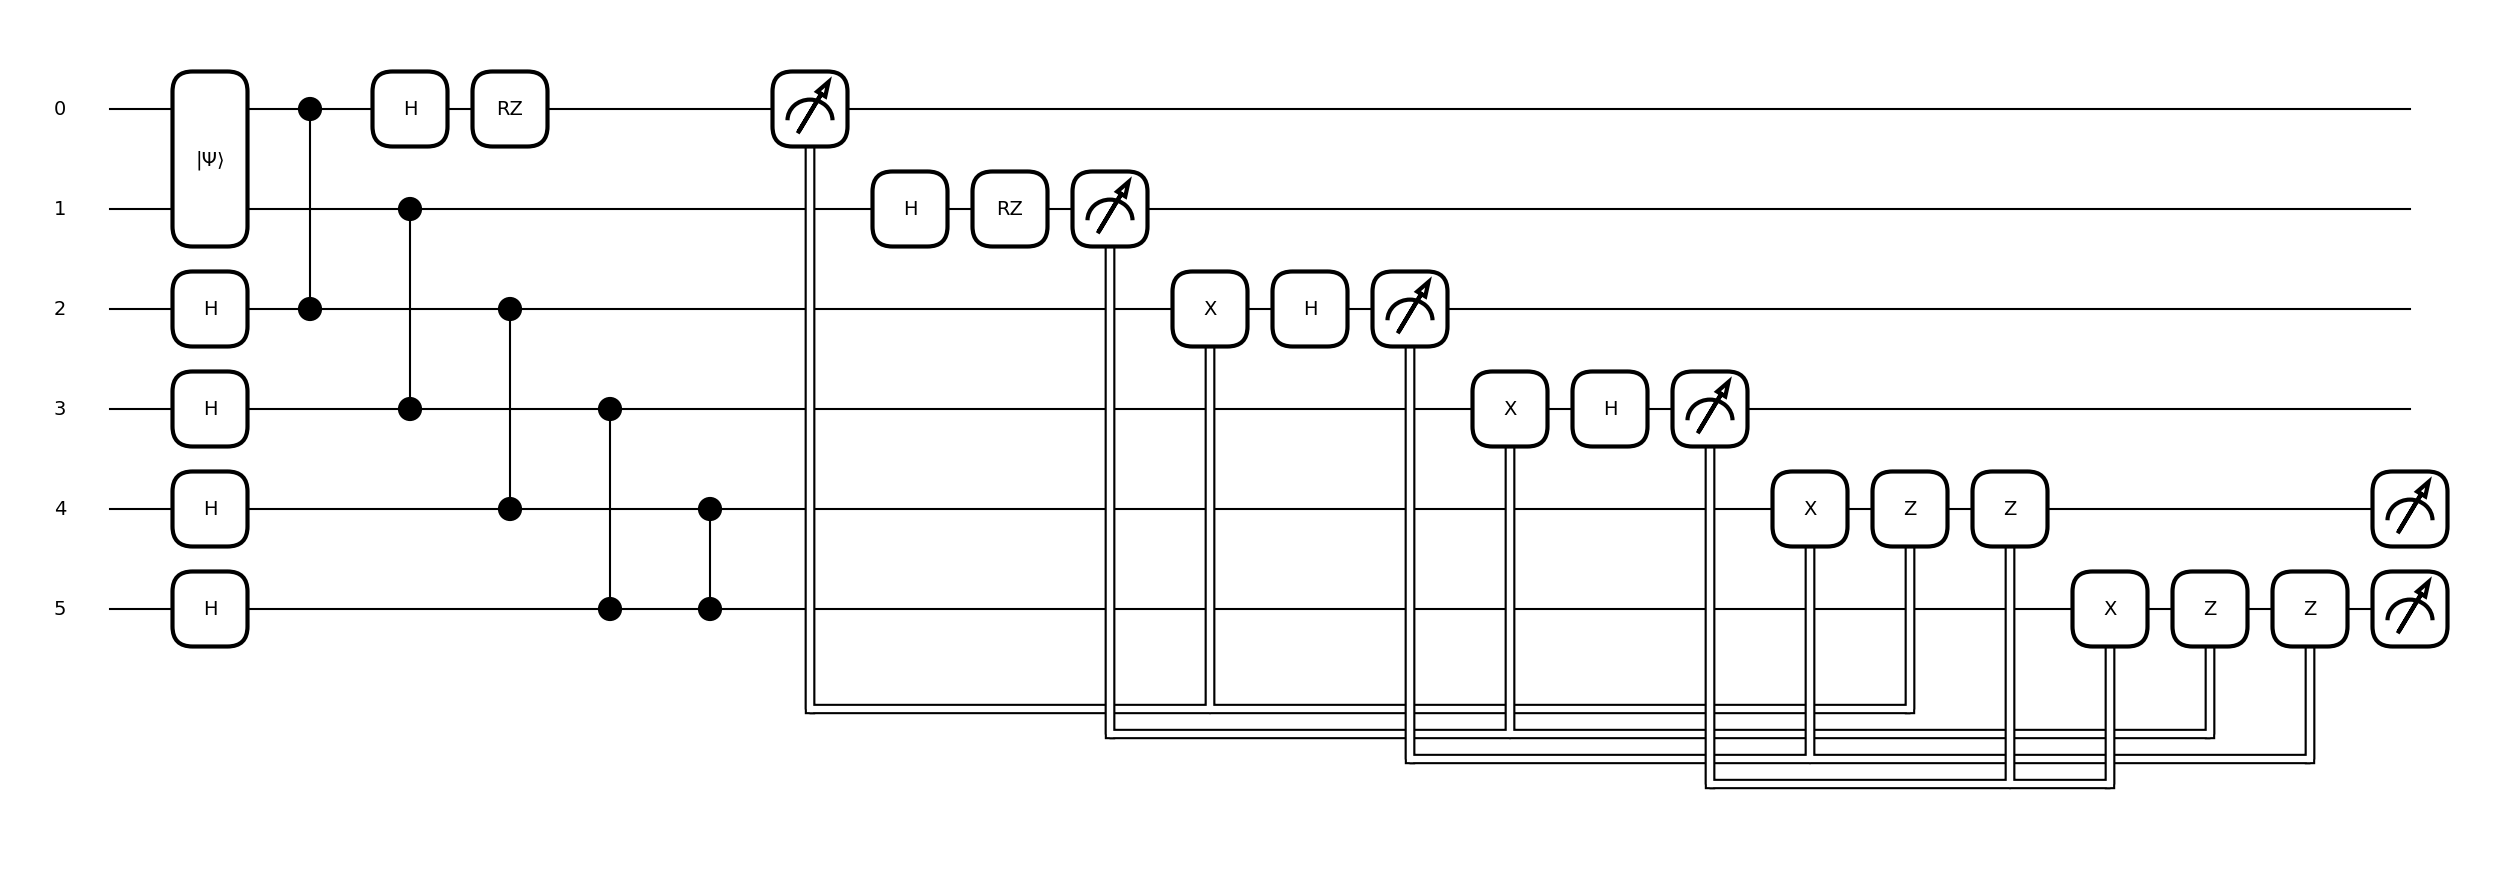

[[ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]
 [-0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]]


In [ ]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt


# MBQC CZ circuit
dev_mbqc = qml.device("default.qubit", wires=6)

@qml.qnode(dev_mbqc, interface="autograd")
def mbqc_cz(input_state):
    # Prepare the same input |ψ⟩ on qubits 0 and 1
    qml.StatePrep(input_state, wires=[0, 1])

    # Prepare ancilla cluster state (qubits 2, 3, 4, 5 in |+⟩ state)
    for w in [2, 3, 4, 5]:
        qml.Hadamard(wires=w)

    # Create cluster entanglement with CZ gates
    qml.CZ(wires=[0, 2])
    qml.CZ(wires=[1, 3])
    qml.CZ(wires=[2, 4])
    qml.CZ(wires=[3, 5])
    qml.CZ(wires=[4, 5])

    # Measure input qubits in X-basis (apply H then measure)
    qml.Hadamard(wires=0)
    qml.RZ(0,wires=0)
    m0 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    qml.RZ(np.pi,wires=1)
    m1 = qml.measure(wires=1)

    # Measure ancilla qubits with byproduct corrections
    qml.cond(m0 == 1, qml.PauliX)(wires=2)
    qml.Hadamard(wires=2)
    m2 = qml.measure(wires=2)

    qml.cond(m1 == 1, qml.PauliX)(wires=3)
    qml.Hadamard(wires=3)
    m3 = qml.measure(wires=3)

    # Apply corrections to output qubits based on measurement outcomes
    qml.cond(m2 == 1, qml.PauliX)(wires=4)
    qml.cond(m0 == 1, qml.PauliZ)(wires=4)
    qml.cond(m3 == 1, qml.PauliZ)(wires=4)

    qml.cond(m3 == 1, qml.PauliX)(wires=5)
    qml.cond(m1 == 1, qml.PauliZ)(wires=5)
    qml.cond(m2 == 1, qml.PauliZ)(wires=5)

    # Return the density matrix of the logical output qubits (4, 5)
    return qml.density_matrix(wires=[4, 5])

input_state = np.array([1, -1, 1, -1], dtype=complex) / 2

fig, ax = qml.draw_mpl(mbqc_cz)(input_state)
plt.show()


print(mbqc_cz(input_state))

# **Two qubit MBQC Subroutine for $|01\rangle$ marked state**

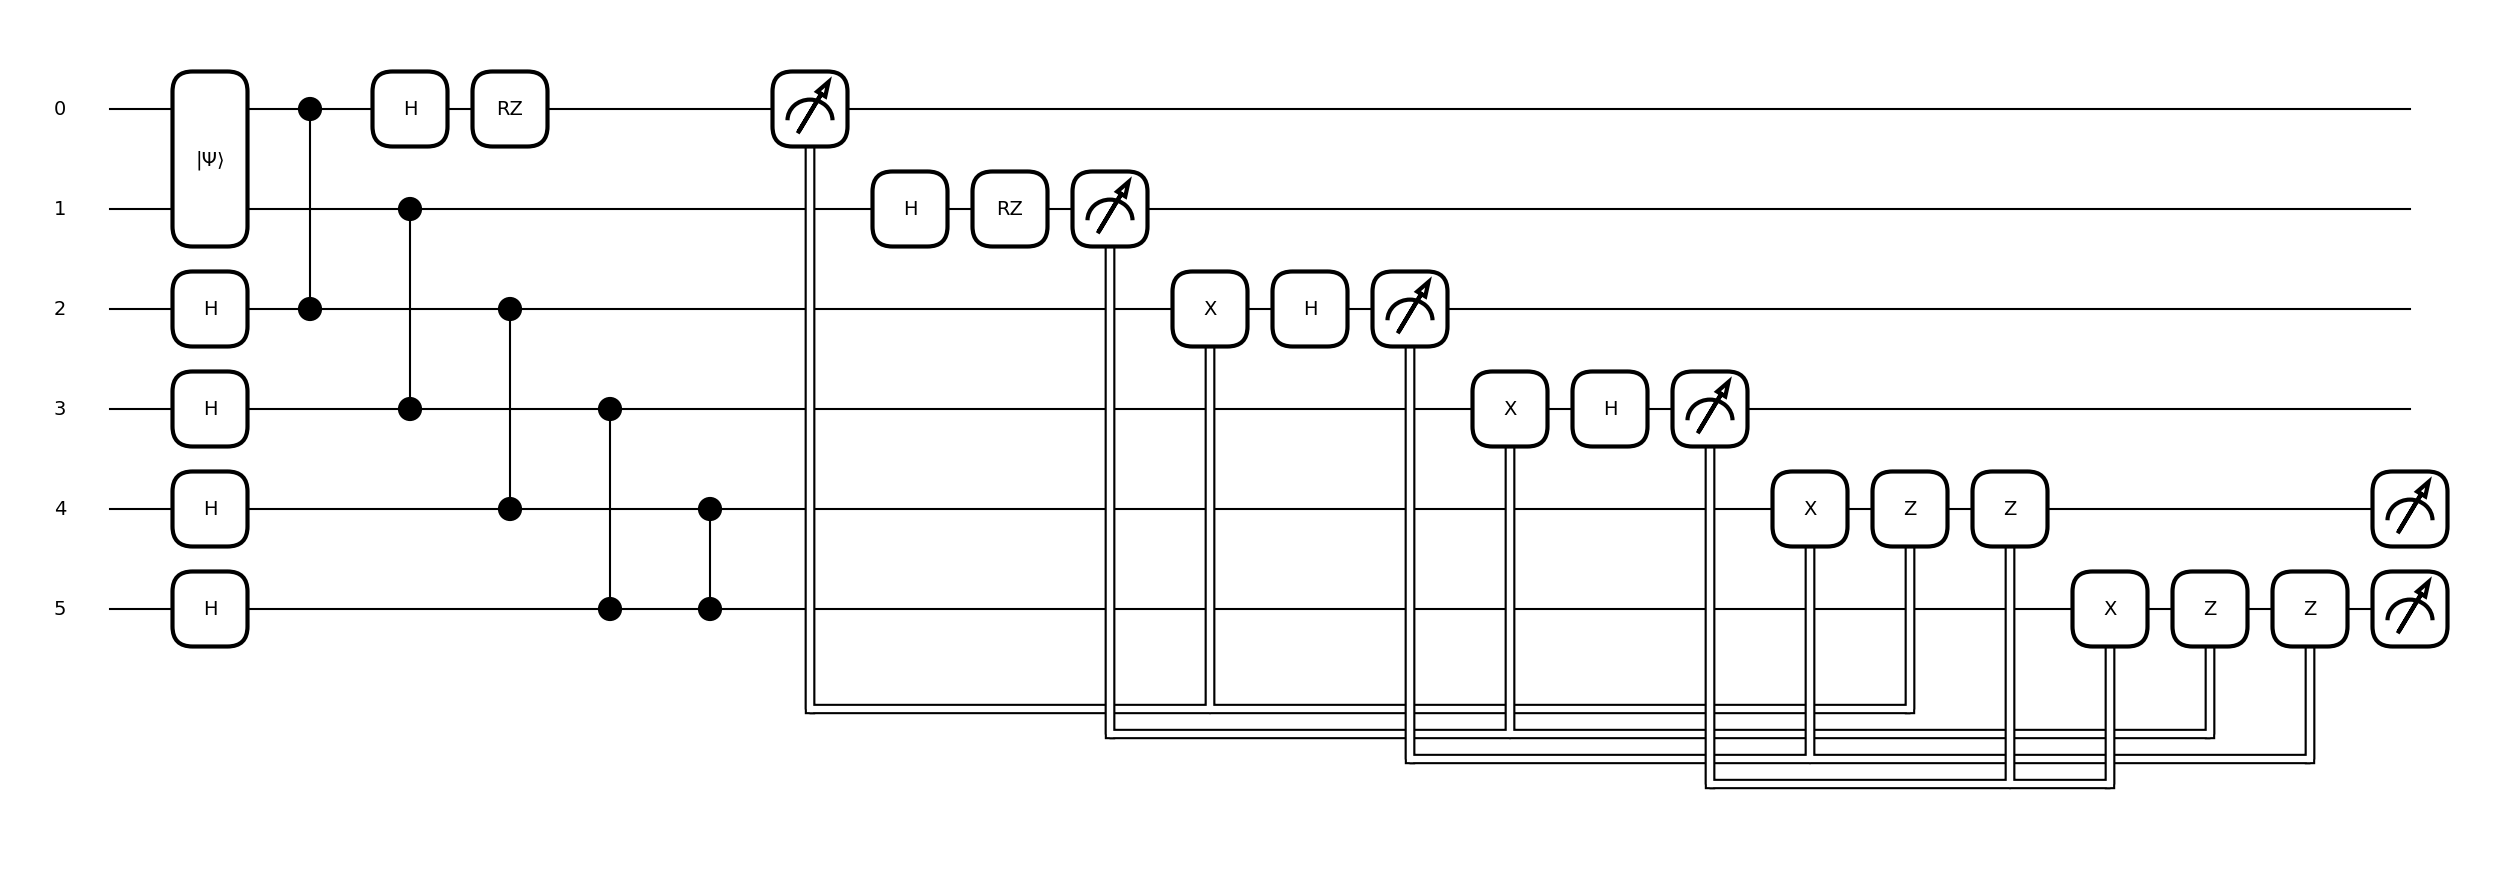

[[ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]
 [-0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]]


In [ ]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt


# MBQC CZ circuit
dev_mbqc = qml.device("default.qubit", wires=6)

@qml.qnode(dev_mbqc, interface="autograd")
def mbqc_cz(input_state):
    # Prepare the same input |ψ⟩ on qubits 0 and 1
    qml.StatePrep(input_state, wires=[0, 1])

    # Prepare ancilla cluster state (qubits 2, 3, 4, 5 in |+⟩ state)
    for w in [2, 3, 4, 5]:
        qml.Hadamard(wires=w)

    # Create cluster entanglement with CZ gates
    qml.CZ(wires=[0, 2])
    qml.CZ(wires=[1, 3])
    qml.CZ(wires=[2, 4])
    qml.CZ(wires=[3, 5])
    qml.CZ(wires=[4, 5])

    # Measure input qubits in X-basis (apply H then measure)
    qml.Hadamard(wires=0)
    qml.RZ(np.pi,wires=0)
    m0 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    qml.RZ(0,wires=1)
    m1 = qml.measure(wires=1)

    # Measure ancilla qubits with byproduct corrections
    qml.cond(m0 == 1, qml.PauliX)(wires=2)
    qml.Hadamard(wires=2)
    m2 = qml.measure(wires=2)

    qml.cond(m1 == 1, qml.PauliX)(wires=3)
    qml.Hadamard(wires=3)
    m3 = qml.measure(wires=3)

    # Apply corrections to output qubits based on measurement outcomes
    qml.cond(m2 == 1, qml.PauliX)(wires=4)
    qml.cond(m0 == 1, qml.PauliZ)(wires=4)
    qml.cond(m3 == 1, qml.PauliZ)(wires=4)

    qml.cond(m3 == 1, qml.PauliX)(wires=5)
    qml.cond(m1 == 1, qml.PauliZ)(wires=5)
    qml.cond(m2 == 1, qml.PauliZ)(wires=5)

    # Return the density matrix of the logical output qubits (4, 5)
    return qml.density_matrix(wires=[4, 5])

input_state = np.array([1, -1, 1, -1], dtype=complex) / 2

fig, ax = qml.draw_mpl(mbqc_cz)(input_state)
plt.show()


print(mbqc_cz(input_state))

# **Two qubit MBQC Subroutine for $|00\rangle$ marked state**

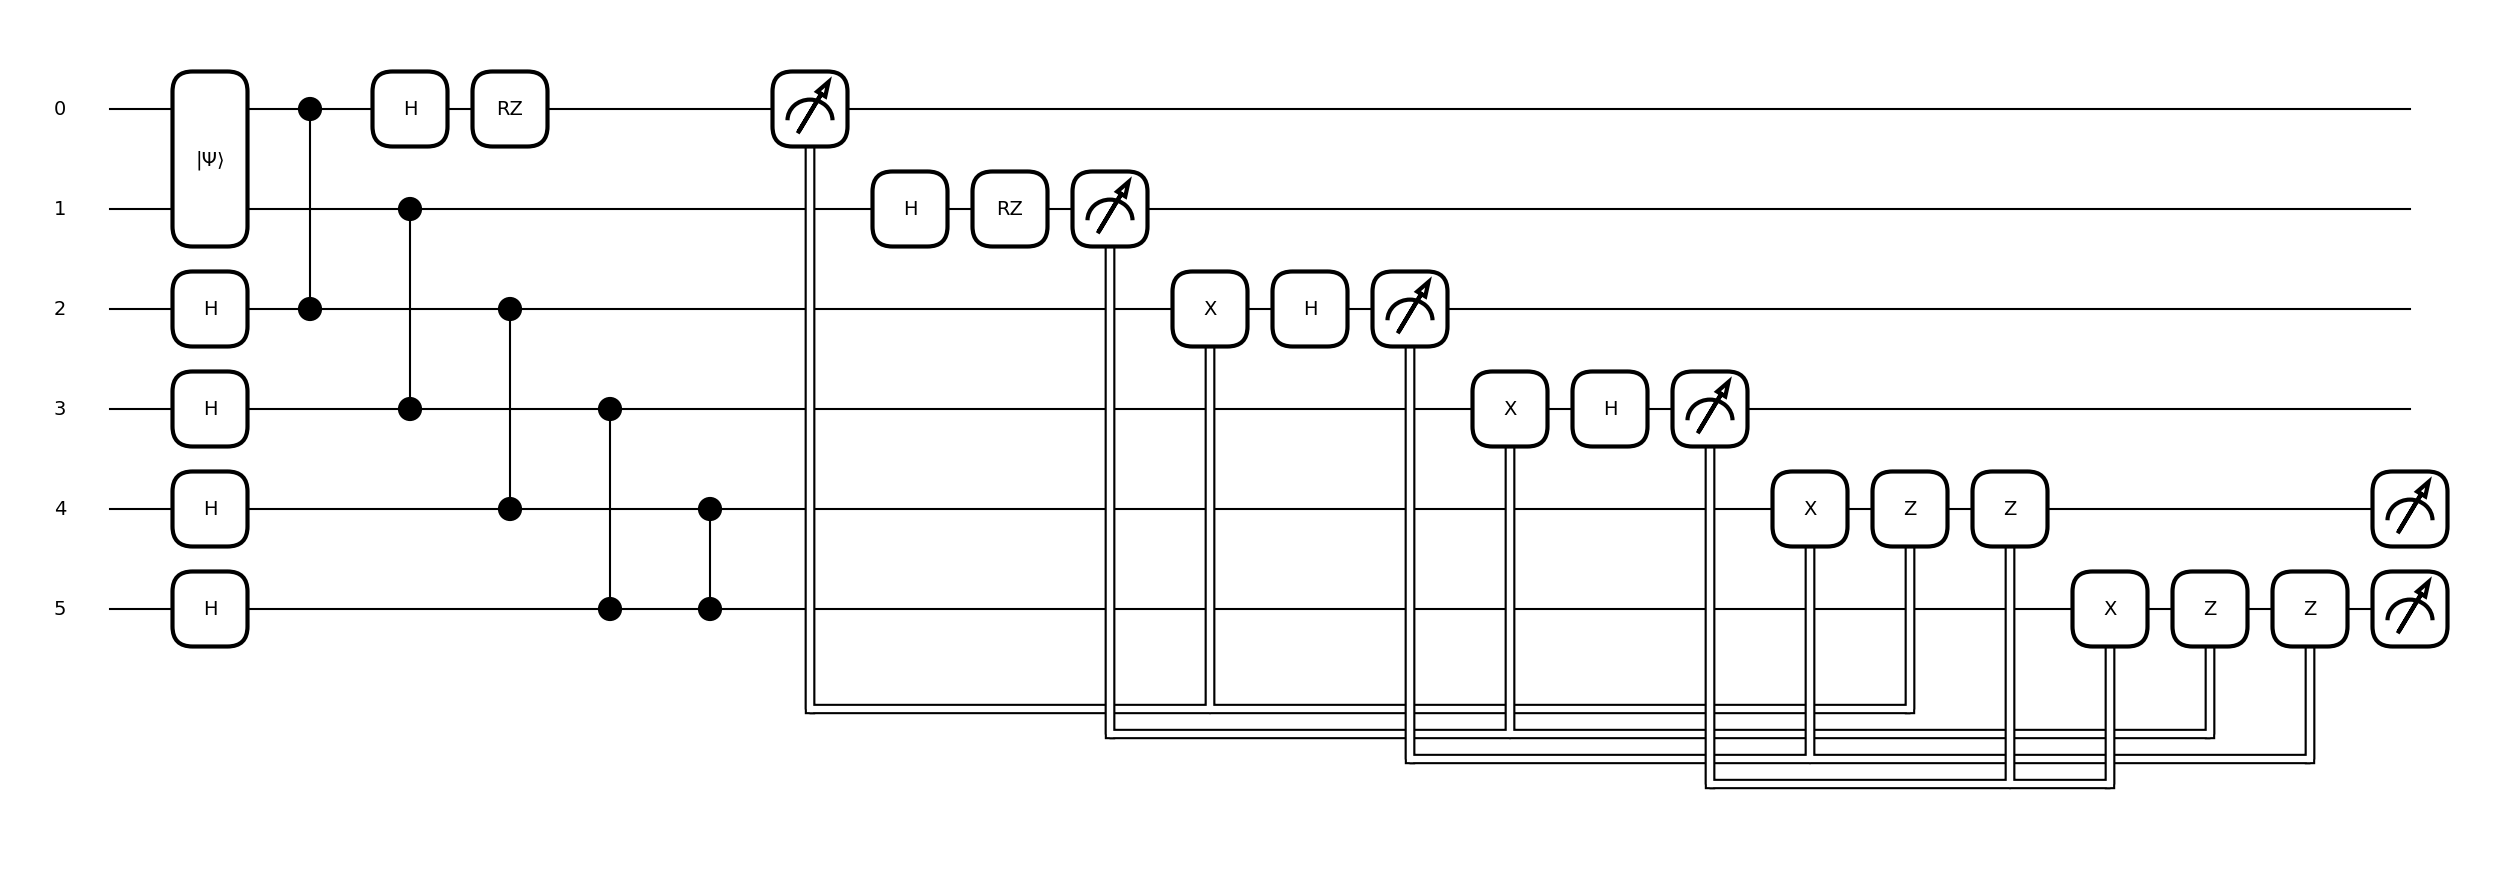

[[ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]
 [-0.25+0.j  0.25+0.j -0.25+0.j -0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]
 [ 0.25+0.j -0.25+0.j  0.25+0.j  0.25+0.j]]


In [ ]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt


# MBQC CZ circuit
dev_mbqc = qml.device("default.qubit", wires=6)

@qml.qnode(dev_mbqc, interface="autograd")
def mbqc_cz(input_state):
    # Prepare the same input |ψ⟩ on qubits 0 and 1
    qml.StatePrep(input_state, wires=[0, 1])

    # Prepare ancilla cluster state (qubits 2, 3, 4, 5 in |+⟩ state)
    for w in [2, 3, 4, 5]:
        qml.Hadamard(wires=w)

    # Create cluster entanglement with CZ gates
    qml.CZ(wires=[0, 2])
    qml.CZ(wires=[1, 3])
    qml.CZ(wires=[2, 4])
    qml.CZ(wires=[3, 5])
    qml.CZ(wires=[4, 5])

    # Measure input qubits in X-basis (apply H then measure)
    qml.Hadamard(wires=0)
    qml.RZ(np.pi,wires=0)
    m0 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    qml.RZ(np.pi,wires=1)
    m1 = qml.measure(wires=1)

    # Measure ancilla qubits with byproduct corrections
    qml.cond(m0 == 1, qml.PauliX)(wires=2)
    qml.Hadamard(wires=2)
    m2 = qml.measure(wires=2)

    qml.cond(m1 == 1, qml.PauliX)(wires=3)
    qml.Hadamard(wires=3)
    m3 = qml.measure(wires=3)

    # Apply corrections to output qubits based on measurement outcomes
    qml.cond(m2 == 1, qml.PauliX)(wires=4)
    qml.cond(m0 == 1, qml.PauliZ)(wires=4)
    qml.cond(m3 == 1, qml.PauliZ)(wires=4)

    qml.cond(m3 == 1, qml.PauliX)(wires=5)
    qml.cond(m1 == 1, qml.PauliZ)(wires=5)
    qml.cond(m2 == 1, qml.PauliZ)(wires=5)

    # Return the density matrix of the logical output qubits (4, 5)
    return qml.density_matrix(wires=[4, 5])

input_state = np.array([1, -1, 1, -1], dtype=complex) / 2

fig, ax = qml.draw_mpl(mbqc_cz)(input_state)
plt.show()


print(mbqc_cz(input_state))